In [9]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parents[0]
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score
from modules.features import HolisticLandmarksFeatureExtracter, FeatureTransformer
from modules.image_annotators import RealLifeTestAnnotator
from modules.model_factory import (SimpleModel,
                                  SimpleModelWithNoise,
                                  SimpleLSTMModel)
from modules.features.transformations import (FeatureWeights, 
                                              FeatureCentering,
                                              FeatureNormalizer,
                                              FeatureRemoveLegData,
                                              FeatureRemoveZCoordinates)

from modules.utilities import load_dataset, transform_dataset, transform_datasets
from modules.process import train_and_validate_model

In [10]:
DATA_PATH: Path = PROJECT_ROOT / 'mp_data'
DATA_PATH_VALIDATION: Path = PROJECT_ROOT / 'mp_data_validation'
DATA_PATH_TEST: Path = PROJECT_ROOT / 'mp_data_new_test'

# TODO: record test data
TEST_DATA_PATH: Path = PROJECT_ROOT / 'mp_data_new_test'
TENSORFLOW_MODEL_PATH: Path = Path('./output_models/simple_model.keras')
NR_OF_EPOCHS: int = 50

feature_extracter = HolisticLandmarksFeatureExtracter()

feature_transformer_none = FeatureTransformer()
feature_transformer_normalized = FeatureTransformer([FeatureNormalizer()])
feature_transformer_weighted = FeatureTransformer([FeatureWeights(10.0, 10.0, 2.0, 0.5)])
feature_transformer_centered = FeatureTransformer([FeatureCentering()])
feature_transformer_no_z_index = FeatureTransformer([FeatureRemoveZCoordinates()])
feature_transformer_all = FeatureTransformer([FeatureRemoveLegData(), FeatureRemoveZCoordinates(), FeatureNormalizer(), FeatureCentering(), FeatureWeights(10.0, 10.0, 2.0, 0.5)])

model_factory = SimpleModel()

In [11]:
# load data
raw_data, labels, actions = load_dataset(DATA_PATH, 
                                             feature_extracter=feature_extracter)

raw_validation, validation_labels, actions_validation = load_dataset(DATA_PATH_VALIDATION,
                                                feature_extracter=feature_extracter)

normalized_data, normalized_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_normalized)
weighted_data, weighted_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_weighted)
centered_data, centered_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_centered)
no_z_index_data, no_z_index_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_no_z_index)

all_transformations_data, all_transformations_validation = transform_datasets(datasets=[raw_data, raw_validation], feature_transformer=feature_transformer_all)

In [12]:
baseline_model, baseline_training = train_and_validate_model(model_factory=model_factory,
                         actions=actions,
                         train_dataset=raw_data,
                         train_labels=labels,
                         validation_dataset=raw_validation,
                         validation_labels=validation_labels,
                         nr_of_epochs=NR_OF_EPOCHS)

normalized_model, normalized_training = train_and_validate_model(model_factory=model_factory,
                            actions=actions,
                            train_dataset=normalized_data,
                            train_labels=labels,
                            validation_dataset=normalized_validation,
                            validation_labels=validation_labels,
                            nr_of_epochs=NR_OF_EPOCHS)

weighted_model, weighted_training = train_and_validate_model(model_factory=model_factory,
                            actions=actions,
                            train_dataset=weighted_data,
                            train_labels=labels,
                            validation_dataset=weighted_validation,
                            validation_labels=validation_labels,
                            nr_of_epochs=NR_OF_EPOCHS)

centered_model, centered_training = train_and_validate_model(model_factory=model_factory,
                            actions=actions,
                            train_dataset=centered_data,
                            train_labels=labels,
                            validation_dataset=centered_validation,
                            validation_labels=validation_labels,
                            nr_of_epochs=NR_OF_EPOCHS)

no_z_index_model, no_z_index_training = train_and_validate_model(model_factory=model_factory,
                            actions=actions,
                            train_dataset=no_z_index_data,
                            train_labels=labels,
                            validation_dataset=no_z_index_validation,
                            validation_labels=validation_labels,
                            nr_of_epochs=NR_OF_EPOCHS)

all_transformations_model, all_transformations_training = train_and_validate_model(model_factory=model_factory,
                            actions=actions,
                            train_dataset=all_transformations_data,
                            train_labels=labels,
                            validation_dataset=all_transformations_validation,
                            validation_labels=validation_labels,
                            nr_of_epochs=NR_OF_EPOCHS)


Actions: ['idle', 'poes', 'slapen', 'vogel']
Number of sequences: 120
Number of classes: 4
Input shape: (120, 30, 1659)
Input dtype: float32
NaN values: 0
Infinite values: 0
Epoch 1/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 224ms/step - categorical_accuracy: 0.2583 - loss: 1.4572 - val_categorical_accuracy: 0.2500 - val_loss: 1.3615
Epoch 2/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - categorical_accuracy: 0.3417 - loss: 1.3719 - val_categorical_accuracy: 0.2500 - val_loss: 1.3382
Epoch 3/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - categorical_accuracy: 0.2750 - loss: 1.3943 - val_categorical_accuracy: 0.4750 - val_loss: 1.2992
Epoch 4/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - categorical_accuracy: 0.4500 - loss: 1.2952 - val_categorical_accuracy: 0.5000 - val_loss: 1.2706
Epoch 5/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - categorical_accuracy: 0.4167 - loss: 1.3162 - val_categorical_accuracy: 0.4917 - val_loss: 1.2453
Epoch 6/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - categorical_accuracy: 0.5000 

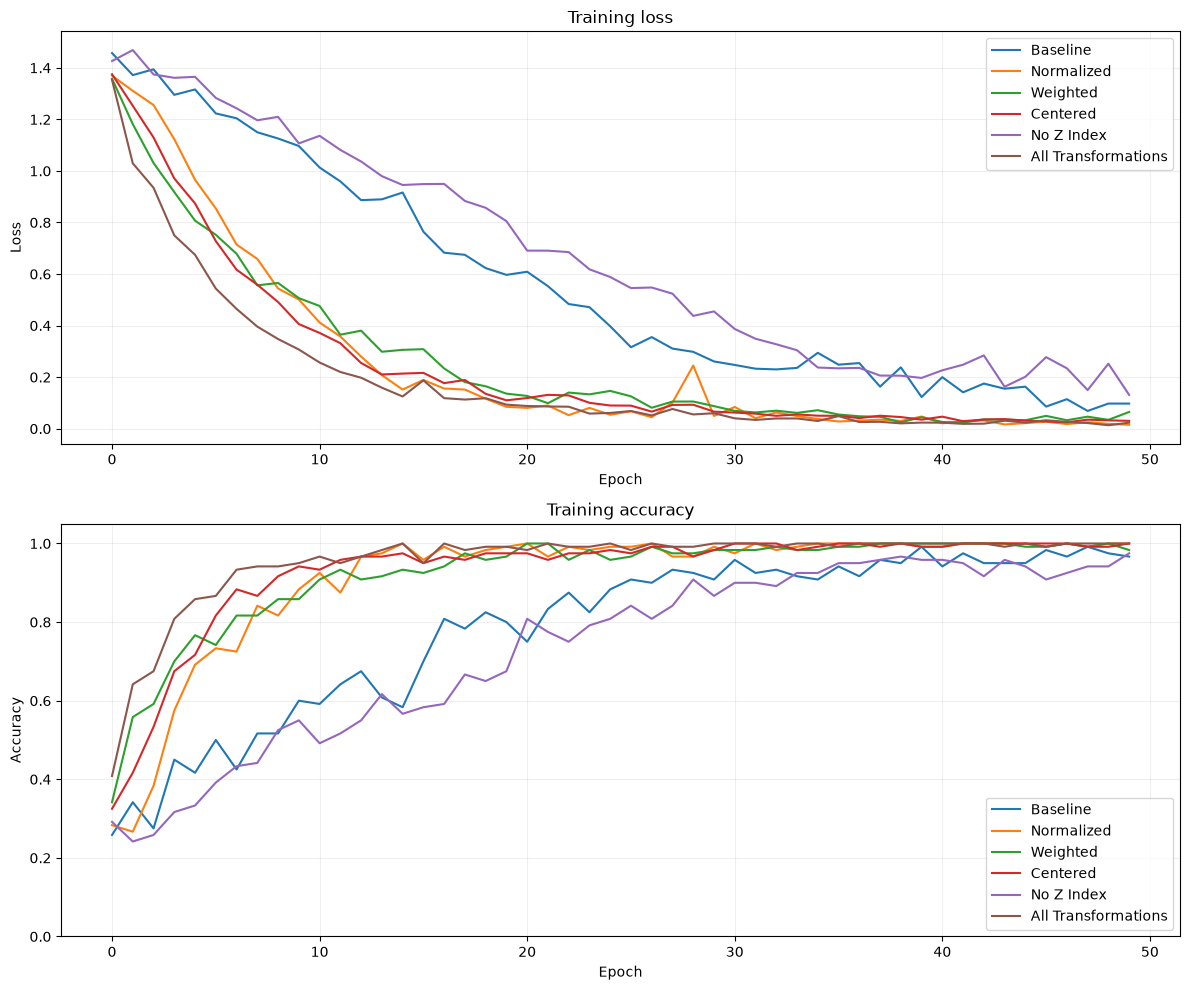

In [ ]:
linestyles = ["-", "--", "-.", ":", (0, (5, 1)), (0, (3, 1, 1, 1))]

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

for (label, history), linestyle in zip(
    [
        ("Baseline", baseline_training),
        ("Normalized", normalized_training),
        ("Weighted", weighted_training),
        ("Centered", centered_training),
        ("No Z Index", no_z_index_training),
        ("All Transformations", all_transformations_training)
    ],
    linestyles
):
    axes[0].plot(history.history["loss"], label=label, linestyle=linestyle)
    axes[1].plot(history.history["categorical_accuracy"], label=label, linestyle=linestyle)

axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Loss")
axes[1].set(title="Training accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1.05))

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [14]:
def predictions(model, x):
    return np.argmax(model.predict(x, verbose=0), axis=1)

# load data
raw_test, test_labels, actions = load_dataset(DATA_PATH_TEST, 
                                              feature_extracter=feature_extracter,
                                              fearure_transformer=feature_transformer_all)

test_transformed = transform_dataset(raw_test, feature_transformer=feature_transformer_all)

original_base_pred = predictions(baseline_model, raw_test)
original_norm_pred = predictions(normalized_model, test_transformed)
original_results = {
    "Baseline": accuracy_score(test_labels, original_base_pred),
    "Normalized": accuracy_score(test_labels, original_norm_pred),
}
print("Original test set (n=%d):" % len(test_labels), original_results)
print("Difference in percentage points:", round(100 * (original_results["Normalized"] - original_results["Baseline"]), 2))

TypeError: load_dataset() got an unexpected keyword argument 'fearure_transformer'